# Bankruptcy Risk Prediction

For this project, I used financial data from Polish companies to predict whether a company would go bankrupt. I compared Random Forest and Gradient Boosting models and focused on how class imbalance affected the results. Since bankruptcies were rare in the dataset, I looked at precision and recall instead of relying only on accuracy.

This project is based on concepts I learned through the WorldQuant University Applied Data Science Lab

In [1]:
!pip install -q ucimlrepo imbalanced-learn

## 1. Load data and inspect imbalance

I used the 3-year cohort from the Polish Companies Bankruptcy dataset. Before building the models, I checked the number of bankrupt companies and the amount of missing data.

Observations: 10,503; predictors: 64; bankrupt: 495 (4.71%)
Missing values: 9888


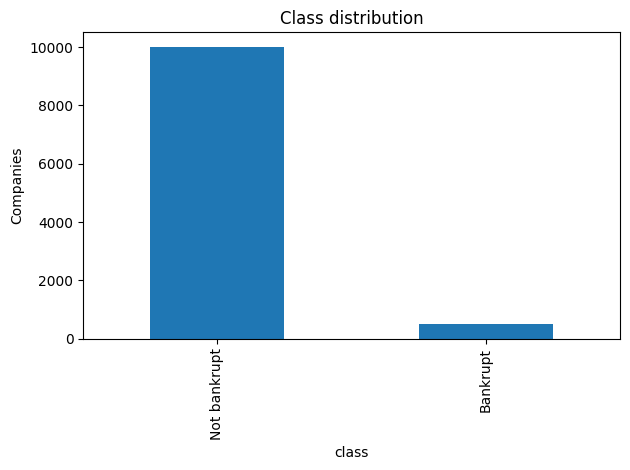

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score, classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay

RANDOM_STATE = 42
dataset = fetch_ucirepo(id=365)
X_all = dataset.data.features.copy()
y_all = dataset.data.targets.squeeze().astype(int)
mask = X_all["year"].eq(3)
X = X_all.loc[mask].drop(columns="year").replace([np.inf, -np.inf], np.nan)
y = y_all.loc[mask]
print(f"Observations: {len(X):,}; predictors: {X.shape[1]}; bankrupt: {int(y.sum()):,} ({y.mean():.2%})")
print("Missing values:", int(X.isna().sum().sum()))
y.value_counts().sort_index().rename(index={0:"Not bankrupt",1:"Bankrupt"}).plot.bar(title="Class distribution")
plt.ylabel("Companies")
plt.tight_layout()
plt.show()

Only 495 of the 10,503 companies went bankrupt, which is about 4.7% of the dataset. This showed that the classes were heavily imbalanced, so accuracy alone would not be a good way to compare the models.

## 2. Holdout split

I split the data into 80% training and 20% testing. I used a stratified split so the percentage of bankrupt companies stayed about the same in both groups. I also did the split before resampling so the test data stayed separate from the training process.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Training:", X_train.shape, "Test:", X_test.shape)

Training: (8402, 64) Test: (2101, 64)


## 3. Random Forest and Gradient Boosting

I compared Random Forest and Gradient Boosting classifiers. Since the bankruptcy class was much smaller, I oversampled the bankrupt companies in the training data. Missing values were also handled as part of the model pipeline.


Random Forest
               precision    recall  f1-score   support

           0       0.96      0.99      0.98      2002
           1       0.62      0.21      0.32        99

    accuracy                           0.96      2101
   macro avg       0.79      0.60      0.65      2101
weighted avg       0.95      0.96      0.95      2101



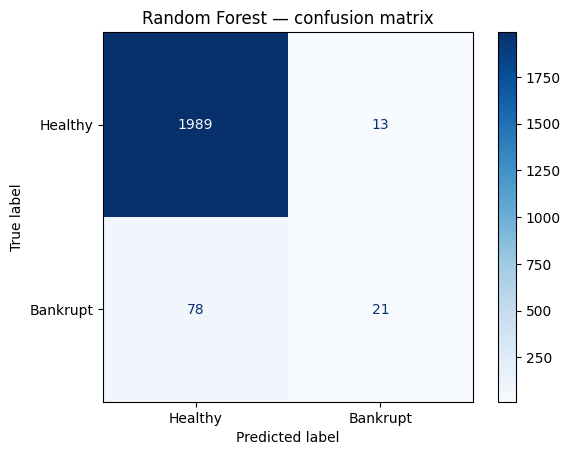


Gradient Boosting
               precision    recall  f1-score   support

           0       0.98      0.96      0.97      2002
           1       0.43      0.66      0.52        99

    accuracy                           0.94      2101
   macro avg       0.71      0.81      0.75      2101
weighted avg       0.96      0.94      0.95      2101



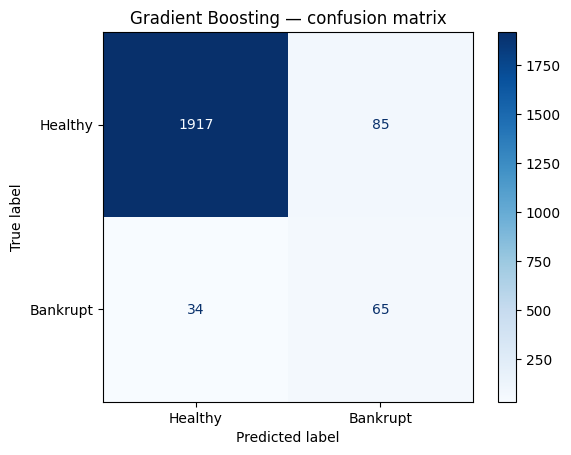

,Precision,Recall,F1,Average precision (PR-AUC)
Model,,,,
Random Forest,0.618,0.212,0.316,0.432
Gradient Boosting,0.433,0.657,0.522,0.638


In [4]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler

models = {
    "Random Forest": ImbPipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("oversample", RandomOverSampler(random_state=RANDOM_STATE)),
        ("classifier", RandomForestClassifier(n_estimators=200, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1)),
    ]),
    "Gradient Boosting": ImbPipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("oversample", RandomOverSampler(random_state=RANDOM_STATE)),
        ("classifier", HistGradientBoostingClassifier(max_iter=150, max_leaf_nodes=15, learning_rate=0.05, random_state=RANDOM_STATE)),
    ]),
}
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    predicted = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted, zero_division=0),
        "F1": f1_score(y_test, predicted, zero_division=0),
        "Average precision (PR-AUC)": average_precision_score(y_test, probability),
    })
    print(f"\n{name}\n", classification_report(y_test, predicted, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, predicted, display_labels=["Healthy", "Bankrupt"], cmap="Blues")
    plt.title(name + " — confusion matrix")
    plt.show()

pd.DataFrame(results).set_index("Model").round(3)

The models gave pretty different results. Random Forest had 96% accuracy, but only found about 21% of the companies that actually went bankrupt. Gradient Boosting had slightly lower accuracy at 94%, but its recall was about 66%, meaning it identified many more of the bankrupt companies. Gradient Boosting also had the higher F1 score and average precision.

## 4. Precision–recall curves and error trade-offs

Because bankruptcies are rare in this dataset, I focused more on precision and recall than overall accuracy. Recall shows how many of the bankrupt companies the model actually found, while precision shows how many companies predicted as bankrupt actually went bankrupt.

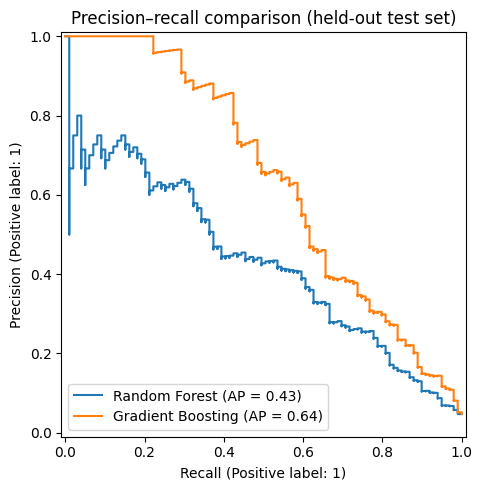

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, model in models.items():
    PrecisionRecallDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.set_title("Precision–recall comparison (held-out test set)")
plt.tight_layout()
plt.show()

Gradient Boosting had an average precision of about 0.64 compared with 0.43 for Random Forest. The precision-recall curve also shows that Gradient Boosting generally gave a better balance between finding bankrupt companies and limiting false positives.

## 5. Model interpretation

I also looked at feature importance for the Random Forest model to see which variables had the most influence on its predictions.

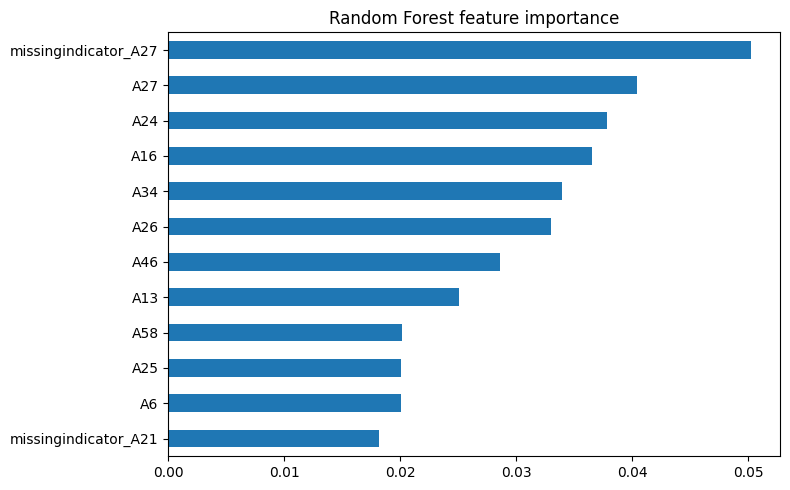

In [6]:
rf = models["Random Forest"]
feature_names = rf.named_steps["impute"].get_feature_names_out(X.columns)
importances = pd.Series(rf.named_steps["classifier"].feature_importances_, index=feature_names)
importances.nlargest(12).sort_values().plot.barh(figsize=(8, 5), title="Random Forest feature importance")
plt.tight_layout()
plt.show()

A27 was one of the most important features, and the missing-value indicator for A27 was actually the highest-ranked feature. This suggests that whether this financial value was missing also gave the model useful information. These importance scores show what the model relied on most, but they do not mean those variables caused bankruptcy.

## 6. Limitations

There are a few limitations to this model. The data only represents one group of companies, so the models could perform differently with data from other years or countries. I also only used one train/test split, so testing the models with cross-validation would give a better idea of how consistent the results are.

The biggest challenge with this dataset was the class imbalance. Since only about 4.7% of the companies went bankrupt, accuracy by itself was not very useful. Gradient Boosting had lower overall accuracy than Random Forest, but it identified many more of the companies that actually went bankrupt.

**Data citation:** Polish Companies Bankruptcy, UCI Machine Learning Repository

**Learning inspiration:** WorldQuant University Applied Data Science Lab, Project 5